In [4]:
import wandb
import pandas as pd
api = wandb.Api()

In [9]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

TITLES = {
    "nt_benchmark": "NT Benchmark",
    "genomic_benchmark": "Genomic Benchmark",
    "bend_benchmark": "BEND Benchmark",
    "chromatin_profile_prediction": "Chromatin Profile Prediction",
}


def _plot_group_diff(ax, df, groups, tasks, baseline, job_type, ci_z=1.96):
    """Barras de diferencia relativa vs baseline + banda de IC 95% del baseline."""
    title = TITLES[job_type]
    if not tasks:
        ax.set_title(f"{title} (sin datos)")
        ax.axis("off")
        return

    # --- medias (groups x tasks) y diferencia relativa, sin loops ---
    means = (df.groupby(["group", "task_label"])["best_score"].mean()
               .unstack().reindex(index=groups, columns=tasks))
    base = means.loc[baseline].where(lambda s: s != 0)          # 0 -> NaN
    rel = means.sub(base, axis=1).div(base, axis=1)

    others = [g for g in groups if g != baseline]
    x = np.arange(len(tasks))
    width = 0.8 / max(len(others), 1)

    for i, grp in enumerate(others):
        vals = rel.loc[grp]
        missing = vals.isna().to_numpy()
        offset = (i - (len(others) - 1) / 2) * width
        bars = ax.bar(x + offset, vals.fillna(0), width, label=grp)
        ax.bar_label(
            bars,
            labels=["skip" if m else f"{v:+.1%}" for m, v in zip(missing, vals)],
            padding=3, fontsize=7, rotation=90,
        )

    # --- banda IC 95% del baseline (en unidades de dif. relativa) ---
    sem = df[df["group"] == baseline].groupby("task_label")["best_score"].sem()  # NaN si n<2
    margin = (ci_z * sem / base.abs()).reindex(tasks)
    first = True
    for j, m in enumerate(margin):
        if np.isfinite(m):
            ax.fill_between([j - 0.4, j + 0.4], -m, m, color="gray", alpha=0.3,
                            lw=0, zorder=9, label="95% CI (baseline)" if first else None)
            first = False

    # --- formato: todo centrado ---
    ax.axhline(0, color="black", lw=0.8)
    ax.set_xticks(x)
    ax.set_xlim(-0.5, len(tasks) - 0.5)                 # grupo centrado en el panel
    if tasks == [job_type]:                             # etiqueta redundante con el título
        ax.tick_params(axis="x", bottom=False, labelbottom=False)
    else:
        ax.set_xticklabels(tasks, rotation=45, ha="right", rotation_mode="anchor")

    ax.margins(y=0.25)                                  # espacio para bar_label
    lim = np.abs(ax.get_ylim()).max()
    ax.set_ylim(-lim, lim)                              # el 0 queda en el centro
    ax.set_ylabel(f"Dif. relativa vs '{baseline}'")
    ax.set_title(title)


def runs_on_task_bar_chart(
    runs_dict,
    baseline_group=None,
    row1_job_type="nt_benchmark",
    row2_job_types=("genomic_benchmark", "bend_benchmark", "chromatin_profile_prediction"),
    row2_width_ratios=None,
    min_width_ratio=2,
    row_height=6,
    width_per_task=0.9,
    save_name=None,
):
    df = pd.DataFrame([
        run.summary._json_dict | {
            "name": run.name, "id": run.id, "tags": run.tags,
            "group": group_name, "job_type": run.job_type,
            "downstream_task": run.config.get("dataset", {}).get("dataset_name"),
            "orients_promoters": run.config.get("canonicalization", {}).get("orient_promoters", False),
        }
        for group_name, runs in runs_dict.items() for run in runs
    ])
    df["task_label"] = df["downstream_task"].fillna(df["job_type"])

    groups = sorted(df["group"].dropna().unique())
    baseline_group = baseline_group or groups[0]
    if baseline_group not in groups:
        raise ValueError(f"baseline_group '{baseline_group}' not found in groups {groups}")

    job_types = [row1_job_type, *row2_job_types]
    tasks = {jt: sorted(df.loc[df["job_type"] == jt, "task_label"].dropna().unique())
             for jt in job_types}

    ratios = list(row2_width_ratios) if row2_width_ratios else \
             [max(len(tasks[jt]), min_width_ratio) for jt in row2_job_types]
    n_cols = len(row2_job_types)
    total_width = max(width_per_task * sum(ratios), width_per_task * min_width_ratio)

    # fila 0 = cabecera (título + leyenda), filas 1-2 = paneles
    fig = plt.figure(figsize=(total_width, row_height * 2.2), layout="constrained")
    gs = fig.add_gridspec(3, n_cols, width_ratios=ratios, height_ratios=[0.2, 1, 1])

    ax_head = fig.add_subplot(gs[0, :])
    ax_head.axis("off")

    axes = [fig.add_subplot(gs[1, :])] + [fig.add_subplot(gs[2, c]) for c in range(n_cols)]
    for ax, jt in zip(axes, job_types):
        _plot_group_diff(ax, df[df["job_type"] == jt], groups, tasks[jt], baseline_group, jt)

    # cabecera: mismo ancho que los ejes => centrada respecto al plot
    ax_head.text(0.5, 0.75, "Differences relative to baseline for canonicalized and leakage control models",
                 ha="center", va="center", fontsize=14, transform=ax_head.transAxes)
    handles, labels = next(((h, l) for ax in axes
                            for h, l in [ax.get_legend_handles_labels()] if h), ([], []))
    if handles:
        ax_head.legend(handles, labels, loc="center", bbox_to_anchor=(0.5, 0.2),
                       ncol=len(labels), fontsize=9, frameon=False)

    if save_name:
        fig.savefig(save_name, dpi=300, bbox_inches="tight")
    plt.show()
    #return fig

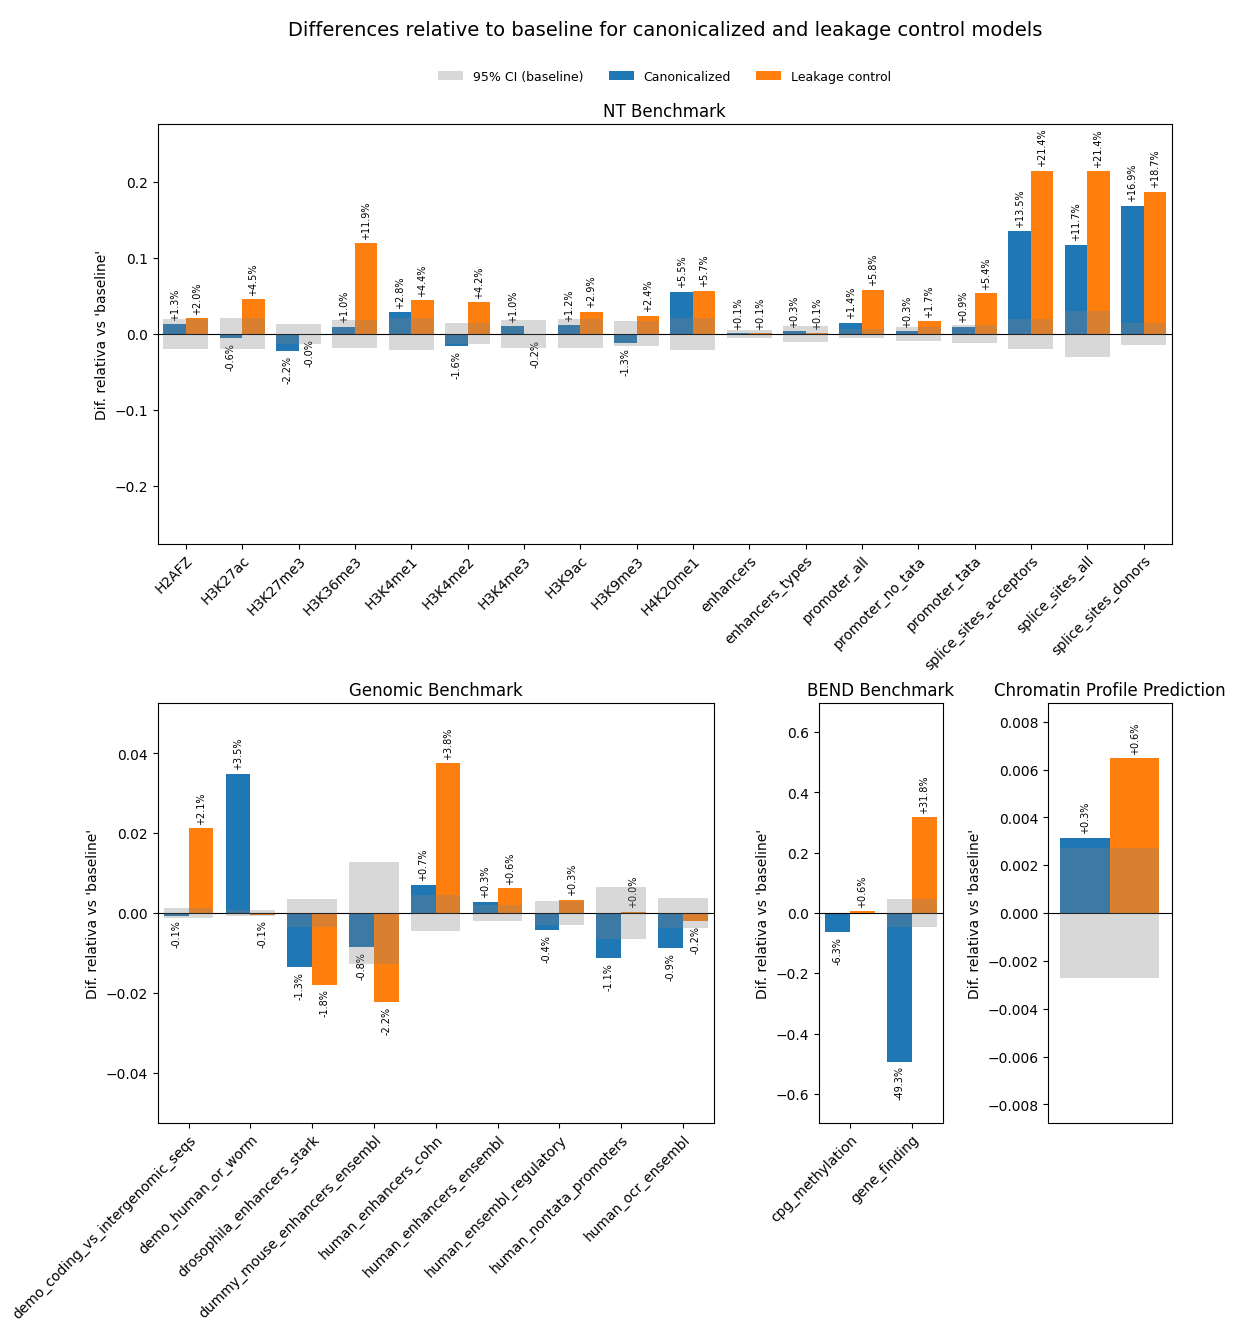

In [10]:
raw_control_signal = api.runs("pipe-verri-gh/Canonicalization", filters={
    "group": "raw_control_signal"
})
canonicalized = api.runs("pipe-verri-gh/Canonicalization", filters={
    "group": "canonicalized"
})
baseline = api.runs("pipe-verri-gh/Canonicalization", filters={
    "group": "baseline"
})

runs_on_task_bar_chart({"Canonicalized": canonicalized, "Leakage control": raw_control_signal, "baseline": baseline}, baseline_group="baseline", save_name="ablation.png")

In [19]:
from scipy import stats

REQUIRED = ("baseline", "canonicalized", "raw_control_signals")

def _pvalue_table(df, metric):
    """p-values right-tail (canon > baseline, canon > raw) por (job_type, task)."""
    rows = []
    for (jt, task), g in df.groupby(["job_type", "task_label"]):
        s = {k: g.loc[g["group"] == k, metric].dropna() for k in REQUIRED}
        if all(len(v) >= 2 for v in s.values()):
            p1 = stats.ttest_ind(s["canonicalized"], s["baseline"], alternative="greater").pvalue
            p2 = stats.ttest_ind(s["canonicalized"], s["raw_control_signals"], alternative="greater").pvalue
        else:
            p1 = p2 = np.nan
        rows.append({"job_type": jt, "task": task,
                     "p_canon_gt_baseline": p1, "p_canon_gt_raw_control": p2})
    res = pd.DataFrame(rows)
    res["max_p"] = res[["p_canon_gt_baseline", "p_canon_gt_raw_control"]].max(axis=1, skipna=False)
    return res


def _plot_pvalues(ax, res, job_type, alpha):
    sub = res[res["job_type"] == job_type].sort_values("task")
    title = TITLES[job_type]
    if sub.empty:
        ax.set_title(f"{title} (sin datos)")
        ax.axis("off")
        return

    tasks = sub["task"].tolist()
    x = np.arange(len(tasks))
    p = sub["max_p"].to_numpy()
    missing = np.isnan(p)

    bars = ax.bar(x, np.nan_to_num(p), width=0.6, color="steelblue")
    ax.bar_label(bars, labels=["skip" if m else f"{v:.3f}" for m, v in zip(missing, p)],
                 padding=3, fontsize=7)

    ax.set_xticks(x)
    ax.set_xlim(-0.5, len(tasks) - 0.5)
    if tasks == [job_type]:
        ax.tick_params(axis="x", bottom=False, labelbottom=False)
    else:
        ax.set_xticklabels(tasks, rotation=45, ha="right", rotation_mode="anchor")

    ax.set_ylim(0, 1.2)
    ax.set_yticks(np.linspace(0, 1, 6))
    ax.set_ylabel(r"$\max\left(p_{\mathrm{baseline}},\ p_{\mathrm{leakage}}\right)$")
    ax.set_title(title)


def canon_vs_controls_pvalue_bar_chart(
    runs_dict,
    metric="best_score",
    alpha=0.05,
    row1_job_type="nt_benchmark",
    row2_job_types=("genomic_benchmark", "bend_benchmark", "chromatin_profile_prediction"),
    row2_width_ratios=None,
    min_width_ratio=2,
    row_height=5,
    width_per_task=0.9,
    save_name=None,
):
    """
    runs_dict: keys 'baseline', 'canonicalized', 'raw_control_signals' -> listas de wandb runs.
    Por task: p1 = P(canon > baseline), p2 = P(canon > raw_control) (t-test cola derecha);
    se grafica max(p1, p2), agrupado por job_type igual que runs_on_task_bar_chart.
    """
    df = pd.DataFrame([
        run.summary._json_dict | {
            "group": group_name,
            "job_type": run.job_type,
            "downstream_task": (
                run.job_type if run.job_type == "chromatin_profile_prediction"
                else run.config.get("dataset", {}).get("dataset_name")
            ),
        }
        for group_name, runs in runs_dict.items() for run in runs
    ])

    missing_groups = set(REQUIRED) - set(df["group"].dropna().unique())
    if missing_groups:
        raise ValueError(f"Faltan grupos en runs_dict: {missing_groups}")

    df["task_label"] = df["downstream_task"].fillna(df["job_type"])
    res = _pvalue_table(df, metric)

    job_types = [row1_job_type, *row2_job_types]
    n_tasks = {jt: (res["job_type"] == jt).sum() for jt in job_types}
    ratios = list(row2_width_ratios) if row2_width_ratios else \
             [max(n_tasks[jt], min_width_ratio) for jt in row2_job_types]
    n_cols = len(row2_job_types)
    total_width = max(width_per_task * sum(ratios), width_per_task * min_width_ratio)

    fig = plt.figure(figsize=(total_width, row_height * 2.2), layout="constrained")
    gs = fig.add_gridspec(3, n_cols, width_ratios=ratios, height_ratios=[0.2, 1, 1])

    ax_head = fig.add_subplot(gs[0, :])
    ax_head.axis("off")

    axes = [fig.add_subplot(gs[1, :])] + [fig.add_subplot(gs[2, c]) for c in range(n_cols)]
    for ax, jt in zip(axes, job_types):
        _plot_pvalues(ax, res, jt, alpha)

    ax_head.text(
        0.5, 0.75,
        r"Worst $p$-value (right-tail $t$-test) of canonicalized $>$ baseline / leakage control, per task",
        ha="center", va="center", fontsize=14, transform=ax_head.transAxes,
    )
    handles, labels = next(((h, l) for ax in axes
                            for h, l in [ax.get_legend_handles_labels()] if h), ([], []))
    if handles:
        ax_head.legend(handles, labels, loc="center", bbox_to_anchor=(0.5, 0.2),
                       ncol=len(labels), fontsize=9, frameon=False)

    if save_name:
        fig.savefig(save_name, dpi=300, bbox_inches="tight")
    plt.show()

    return res.drop(columns="job_type").assign(job_type=res["job_type"]).reset_index(drop=True)

/tmp/ipykernel_168358/1818822754.py:11: RuntimeWarning: Precision loss occurred in moment calculation due to catastrophic cancellation. This occurs when the data are nearly identical. Results may be unreliable.
  p1 = stats.ttest_ind(s["canonicalized"], s["baseline"], alternative="greater").pvalue
/tmp/ipykernel_168358/1818822754.py:12: RuntimeWarning: Precision loss occurred in moment calculation due to catastrophic cancellation. This occurs when the data are nearly identical. Results may be unreliable.
  p2 = stats.ttest_ind(s["canonicalized"], s["raw_control_signals"], alternative="greater").pvalue


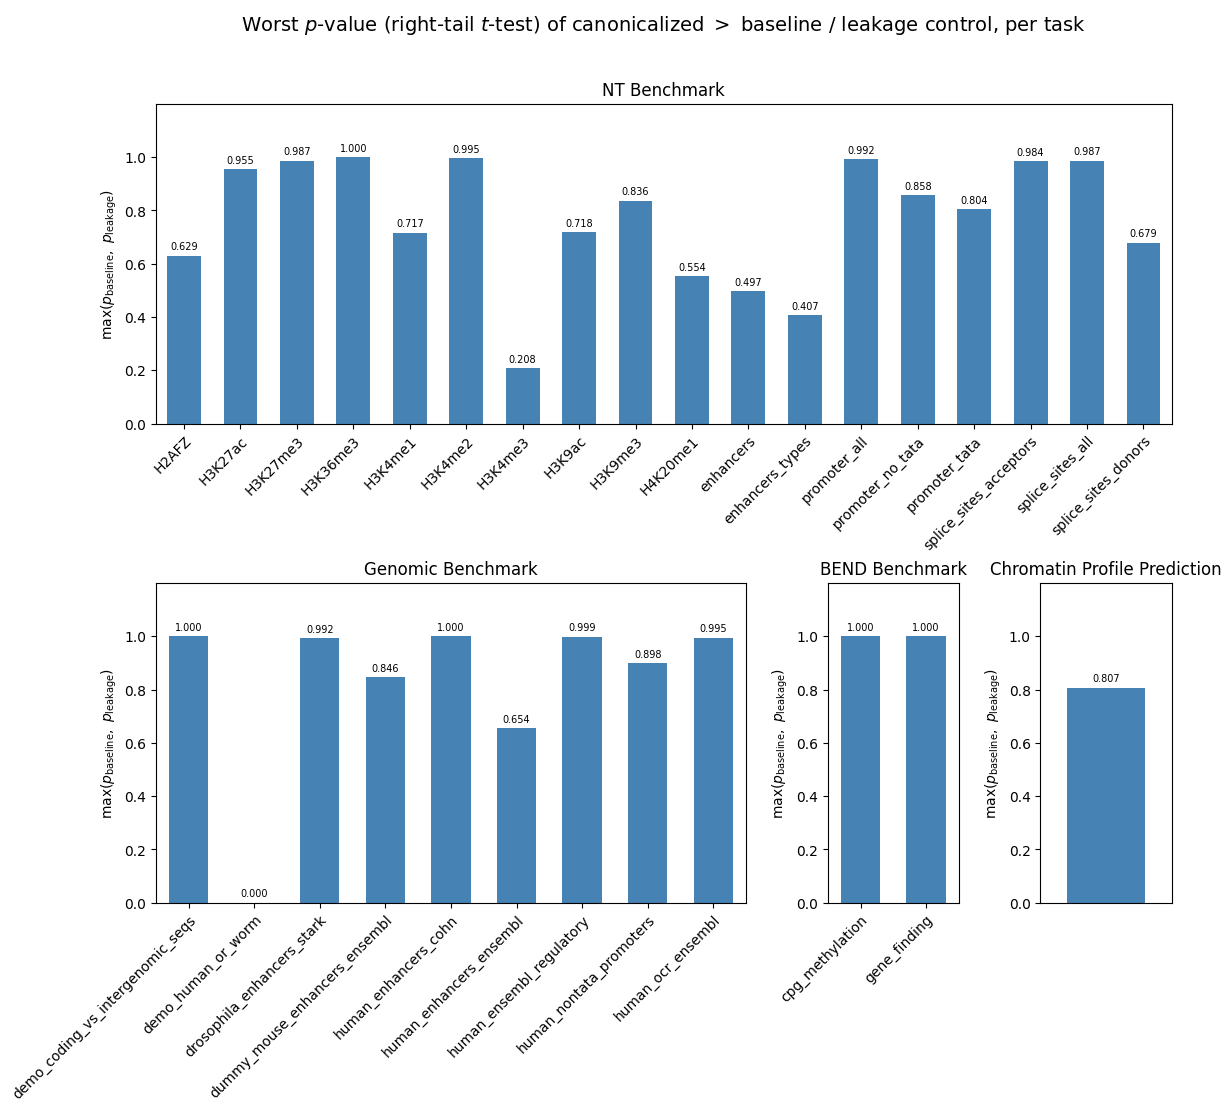

,task,p_canon_gt_baseline,p_canon_gt_raw_control,max_p,job_type
0,cpg_methylation,1.000000e+00,1.000000e+00,1.000000e+00,bend_benchmark
1,gene_finding,9.999886e-01,9.999984e-01,9.999984e-01,bend_benchmark
2,chromatin_profile_prediction,1.391069e-01,8.073921e-01,8.073921e-01,chromatin_profile_prediction
3,demo_coding_vs_intergenomic_seqs,7.836921e-01,1.000000e+00,1.000000e+00,genomic_benchmark
4,demo_human_or_worm,8.781688e-14,2.191962e-11,2.191962e-11,genomic_benchmark
5,drosophila_enhancers_stark,9.917005e-01,2.468156e-01,9.917005e-01,genomic_benchmark
6,dummy_mouse_enhancers_ensembl,8.459962e-01,4.062702e-02,8.459962e-01,genomic_benchmark
7,human_enhancers_cohn,3.140352e-02,9.999979e-01,9.999979e-01,genomic_benchmark
8,human_enhancers_ensembl,3.282118e-01,6.538472e-01,6.538472e-01,genomic_benchmark
9,human_ensembl_regulatory,9.646355e-01,9.989601e-01,9.989601e-01,genomic_benchmark


In [21]:
canon_vs_controls_pvalue_bar_chart({
    "baseline": baseline,
    "canonicalized": canonicalized,
    "raw_control_signals": raw_control_signal
}, save_name="ablation_p_values.png")